In [64]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [65]:
from scipy.stats import zscore
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix,roc_curve,roc_auc_score

In [66]:
df = pd.read_csv("wineQualityReds.csv")

In [67]:
df

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [68]:
df.head()

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [69]:
df.tail()

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed.acidity         1599 non-null   float64
 1   volatile.acidity      1599 non-null   float64
 2   citric.acid           1599 non-null   float64
 3   residual.sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free.sulfur.dioxide   1599 non-null   float64
 6   total.sulfur.dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [71]:
df.describe()

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [72]:
df.isnull().sum()

fixed.acidity           0
volatile.acidity        0
citric.acid             0
residual.sugar          0
chlorides               0
free.sulfur.dioxide     0
total.sulfur.dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [73]:
#C1 : There are no null values present in dataset

In [74]:
print(df.keys())

Index(['fixed.acidity', 'volatile.acidity', 'citric.acid', 'residual.sugar',
       'chlorides', 'free.sulfur.dioxide', 'total.sulfur.dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')


In [75]:
m = pd.DataFrame(df)

In [76]:
m

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [77]:
m.head(5)

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [78]:
#C2 : As per the Dataset we are able to know that we have to predict the quality of our dataset hence quality is our target value .

In [79]:
m["quality"].value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

In [80]:
#C3 : As per the value counts we are able to know that most of the qualities lies between 5 and 6 and where 3 is the least count

<Axes: xlabel='quality', ylabel='count'>

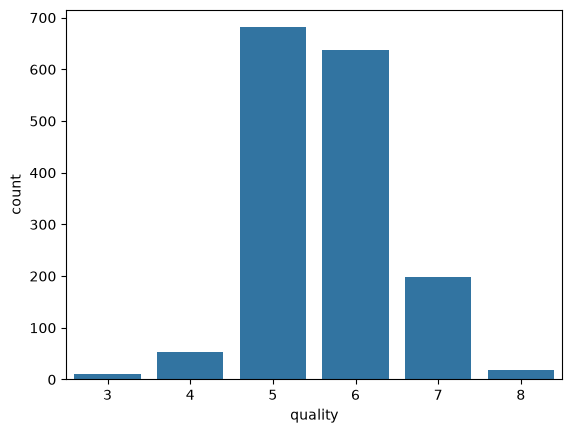

In [81]:
sns.countplot(x = 'quality', data = m)

fixed.acidity              Axes(0.125,0.712609;0.227941x0.167391)
volatile.acidity        Axes(0.398529,0.712609;0.227941x0.167391)
citric.acid             Axes(0.672059,0.712609;0.227941x0.167391)
residual.sugar             Axes(0.125,0.511739;0.227941x0.167391)
chlorides               Axes(0.398529,0.511739;0.227941x0.167391)
free.sulfur.dioxide     Axes(0.672059,0.511739;0.227941x0.167391)
total.sulfur.dioxide        Axes(0.125,0.31087;0.227941x0.167391)
density                  Axes(0.398529,0.31087;0.227941x0.167391)
pH                       Axes(0.672059,0.31087;0.227941x0.167391)
sulphates                      Axes(0.125,0.11;0.227941x0.167391)
alcohol                     Axes(0.398529,0.11;0.227941x0.167391)
quality                     Axes(0.672059,0.11;0.227941x0.167391)
dtype: object

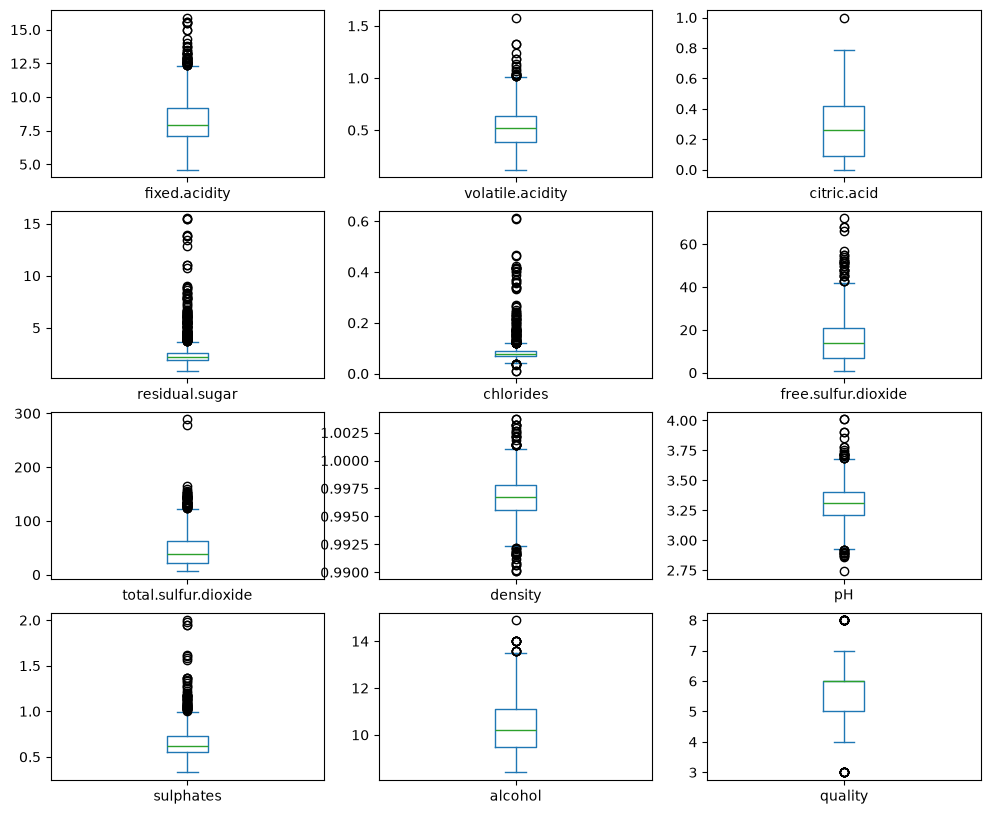

In [82]:
m.plot(kind = 'box',subplots = True ,layout = (4,3),figsize = (12,10))

In [83]:
#C4 : While performing the box plot we are able to know that each of the field has an outlier in which mostly outliers lies in chlorine and residual sugar .

In [84]:
features = m.drop('quality',axis=1)

In [85]:
Z = np.abs(zscore(features))

In [86]:
threshold = 3

In [87]:
b = m[(Z < threshold).all(axis=1)]

In [88]:
b

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [89]:
print('\n shape before outlier removal:',m.shape)
print('\n shape after outlier removal:',b.shape)


 shape before outlier removal: (1599, 12)

 shape after outlier removal: (1458, 12)


In [90]:
print('\n records removed:',m.shape[0],b.shape[0])


 records removed: 1599 1458


In [91]:
#C5 : As there were outliers present we have used zscore method to remove it by setting up threshold value

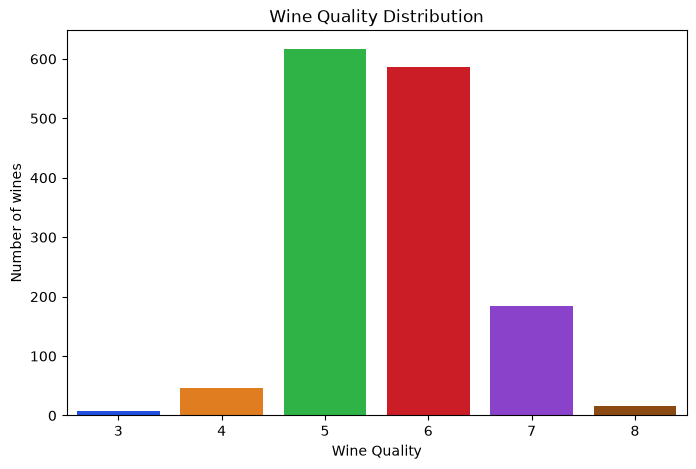

In [92]:
plt.figure(figsize = (8,5))
sns.countplot(x='quality',data = b,palette = 'bright' )
plt.title('Wine Quality Distribution')
plt.xlabel('Wine Quality')
plt.ylabel('Number of wines')
plt.show()

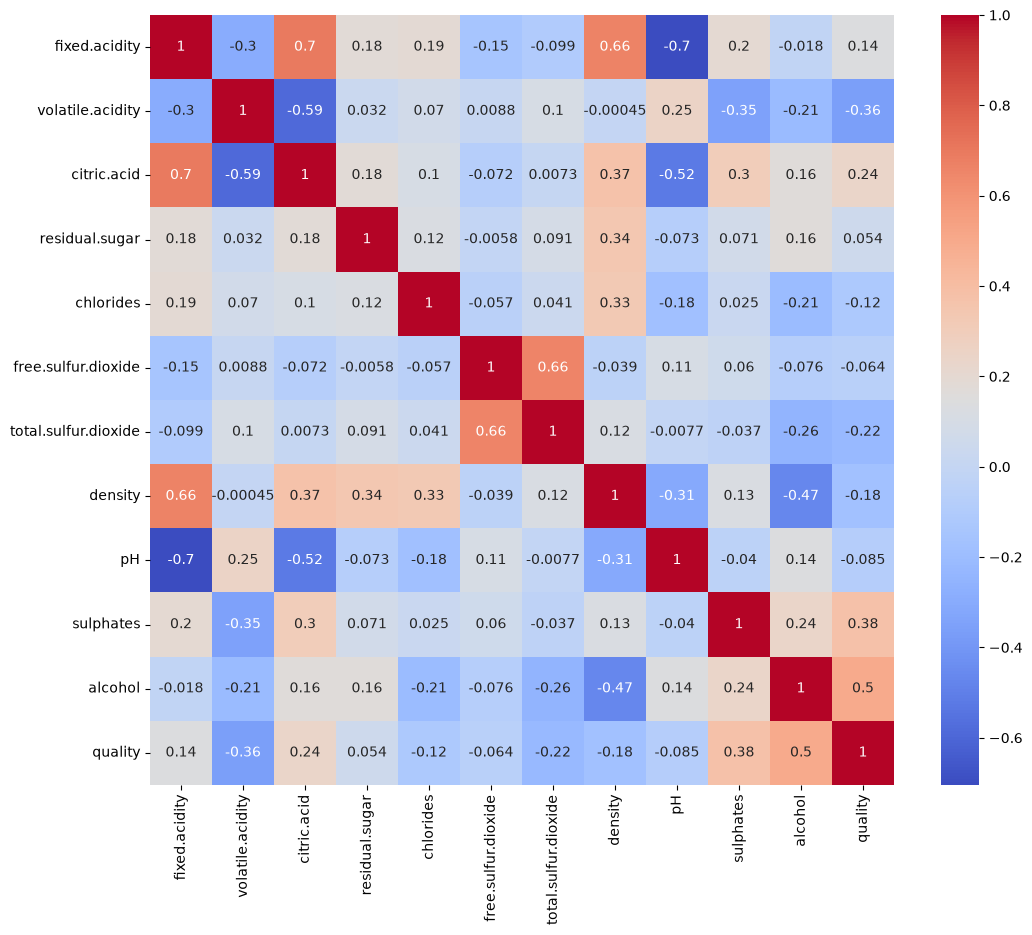

In [93]:
corr = b.corr()
plt.figure(figsize = (12,10))
sns.heatmap(corr, annot = True , cmap ='coolwarm')
plt.show()

In [94]:
b["quality"].value_counts()

quality
5    617
6    586
7    185
4     47
8     16
3      7
Name: count, dtype: int64

In [95]:
x = b.iloc[:,:-1]

In [96]:
y = b['quality'].apply(lambda y_value:1 if y_value >= 7 else 0 )

In [97]:
# Lambda function is anonomous function(without a name) to pass arguement and expression. 

In [98]:
#C6 : As per using lambda function we have segmented the wine quality in the form of 0 and 1 where 1 lies from values > 7 or equal to 7

In [99]:
y.value_counts()

quality
0    1257
1     201
Name: count, dtype: int64

In [100]:
x_train , x_test, y_train , y_test = train_test_split(x,y,test_size=0.20,random_state=42)

In [101]:
x_train.shape

(1166, 11)

In [102]:
y_train.shape

(1166,)

In [103]:
dtc = DecisionTreeClassifier(max_depth = 5, min_samples_split = 10, min_samples_leaf = 5, class_weight = 'balanced',random_state = 42) 

In [104]:
dtc.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are co

In [105]:
pred = dtc.predict(x_test)

In [106]:
pred

array([0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 1])

In [107]:
pre = dtc.predict_proba(x_test)[:,1]

In [108]:
pre

array([0.        , 0.50772515, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.50772515, 0.        , 0.50772515,
       0.58622938, 0.        , 0.        , 0.2660807 , 0.9416075 ,
       0.9416075 , 0.        , 0.        , 0.9416075 , 0.        ,
       0.77174947, 0.86010471, 0.        , 0.        , 0.        ,
       0.26029182, 0.2660807 , 0.        , 0.        , 0.26029182,
       0.        , 0.13009506, 0.        , 0.        , 0.50772515,
       0.58622938, 0.        , 0.49925037, 0.        , 0.        ,
       0.        , 0.86010471, 0.        , 0.        , 0.        ,
       0.        , 0.89972981, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.2660807 , 0.        , 0.77174947, 0.50772515, 0.        ,
       0.        , 0.9416075 , 0.50772515, 0.        , 0.58622938,
       0.2660807 , 0.        , 0.        , 0.58622938, 0.        ,
       0.57991486, 0.50772515, 0.13009506, 0.50772515, 0.58622

In [109]:
accuracy = accuracy_score(y_test, pred)

In [110]:
accuracy

0.7328767123287672

In [111]:
print('Classification Report:', classification_report(y_test, pred))

Classification Report:               precision    recall  f1-score   support

           0       0.97      0.72      0.83       258
           1       0.28      0.85      0.43        34

    accuracy                           0.73       292
   macro avg       0.63      0.78      0.63       292
weighted avg       0.89      0.73      0.78       292



In [112]:
cm = confusion_matrix(y_test, pred)

In [113]:
cm

array([[185,  73],
       [  5,  29]])

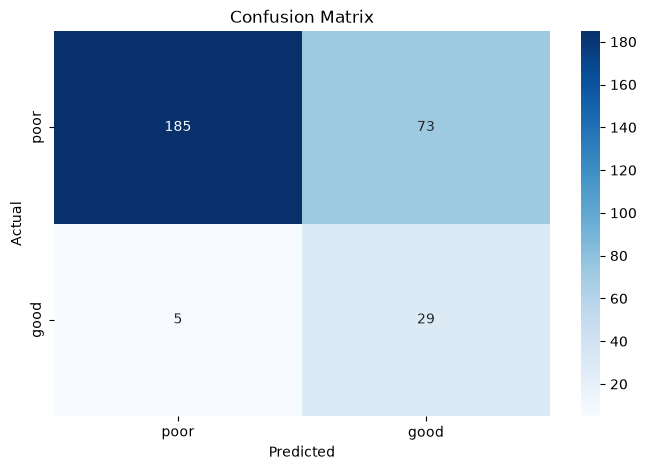

In [114]:
plt.figure(figsize=(8,5))
sns.heatmap(cm, annot = True,fmt ='d', cmap = 'Blues', xticklabels = ['poor','good'],yticklabels = ['poor','good'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [115]:
#ROC curve


In [116]:
fpr,tpr,thresholds = roc_curve(y_test,pred)

In [117]:
print(fpr,tpr,threshold)

[0.         0.28294574 1.        ] [0.         0.85294118 1.        ] 3


In [118]:
auc_score = roc_auc_score(y_test,pred)

In [119]:
auc_score

0.7849977200182398

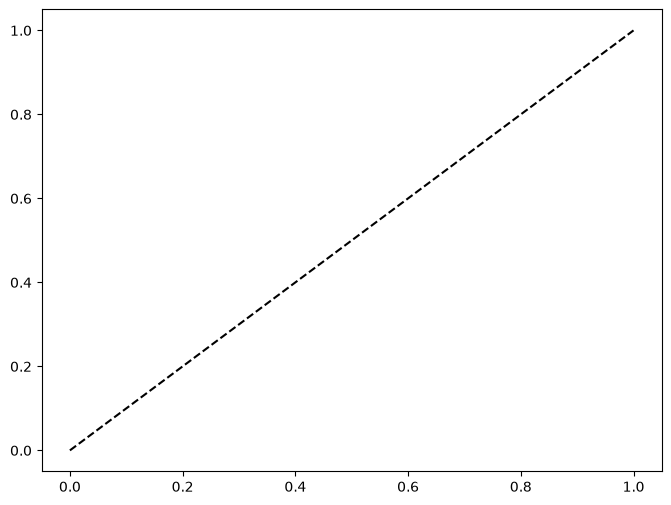

In [120]:
plt.figure(figsize = (8,6))
plt.plot([0,1],[0,1],'k--',label = 'roc curve')

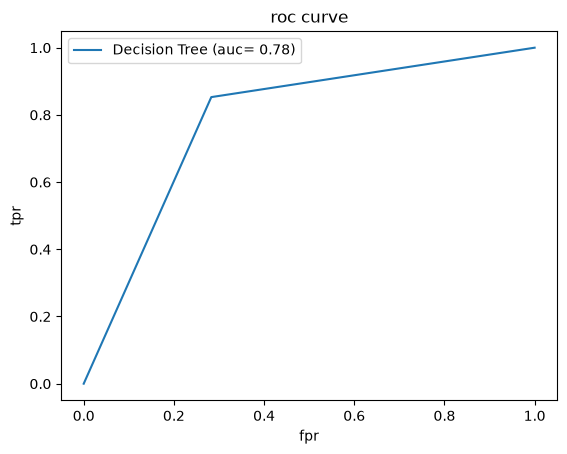

In [121]:
plt.plot(fpr,tpr,label = f"Decision Tree (auc={auc_score: .2f})")
plt.xlabel('fpr')
plt.ylabel('tpr')
plt.title('roc curve')
plt.legend()
plt.show()

In [122]:
def qual(q):
    q = pd.DataFrame([q],columns = x.columns)
    pro = dtc.predict(q)[0]
    probability = dtc.predict_proba(q)[0][1]
    print('Predicted Value:',pro)
    print('Probability Of Good Wine:',probability)
    if pro == 1:
        print('The Wine Quality Is Good')
    else:
        print('The Wine Quality Is Poor')

In [123]:
q = np.array([
    7.3,0.65,0.0,1.2,0.065,15.0,21.0,0.09946,3.39,0.47,10.0])

In [124]:
qual(q)

Predicted Value: 1
Probability Of Good Wine: 0.5992801439712058
The Wine Quality Is Good


In [125]:
# Final Model Summary

print('\n ========================================')
print('         MODEL PERFORMANCE SUMMARY        ')
print('========================================')

print('Model : Decision Tree Classifier')
print('Accuracy :',accuracy)
print('ROC_AUC :',auc_score)

print('/n Target Classification:')
print('0 = Poor Wine (Quality < 7)')
print('1 = Good Wine (Quality >= 7)')

print('\n Project Completed Successfully !')


         MODEL PERFORMANCE SUMMARY        
Model : Decision Tree Classifier
Accuracy : 0.7328767123287672
ROC_AUC : 0.7849977200182398
/n Target Classification:
0 = Poor Wine (Quality < 7)
1 = Good Wine (Quality >= 7)

 Project Completed Successfully !
